# Telegram Android: Turning 22,800 App Reviews into a Prioritised Roadmap

**Product question.** If I were a PM on Telegram for Android in spring 2017, which problems should the team fix next?
Reviews are the largest unprompted source of user feedback, but nobody can read 22,800 of them.

**Data.** 22,816 Google Play reviews of `org.telegram.messenger` (Nov 2016 – May 2017) with star ratings, from the public
*Software Applications User Reviews* dataset (Grano et al., 2017).

**Approach**
1. Rating health over time: find dips and explain them
2. Launch analysis: how users received **voice calls** (launched 30 Mar 2017, rolled out region by region)
3. Theme analysis with an auditable keyword taxonomy (`src/themes.py`), cross-checked with unsupervised topic modelling (NMF)
4. Feature-request mining
5. RICE prioritisation and a PRD for the top item (`reports/PRD_app_stability.md`)

In [1]:
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

sys.path.append("../src")
from style import C, apply_style, save
from themes import THEMES, is_availability_issue, is_request, tag_themes

apply_style()
pd.set_option("display.max_colwidth", 140)

## 1. Load and prepare

In [2]:
allrev = pd.read_csv("../data/raw/reviews.csv", on_bad_lines="skip", engine="python")
df = allrev[allrev["package_name"] == "org.telegram.messenger"].copy()
df["date"] = pd.to_datetime(df["date"], format="%B %d %Y")
df["low"] = df["star"] <= 2
df["review"] = df["review"].astype(str)
print(f"Telegram reviews: {len(df):,} | {df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}")
print(f"Average rating: {df.star.mean():.2f} | 1-2 star share: {df.low.mean():.1%}")
df["star"].value_counts(normalize=True).sort_index().rename("share")

Telegram reviews: 22,816 | 10 Nov 2016 to 02 May 2017
Average rating: 4.39 | 1-2 star share: 9.3%


star
1    0.067146
2    0.025771
3    0.062851
4    0.139551
5    0.704681
Name: share, dtype: float64

In [3]:
themes = tag_themes(df["review"])
df = df.join(themes)
df["request"] = is_request(df["review"])
print(f"Reviews tagged with at least one theme: {themes.any(axis=1).mean():.1%}")

Reviews tagged with at least one theme: 23.8%


## 2. Rating health over time
Weekly average rating and share of 1–2★ reviews. Two dips stand out; the notebook below diagnoses each from the review text.

In [4]:
weekly = df.set_index("date").resample("W").agg(reviews=("star", "size"), avg=("star", "mean"), low=("low", "mean"))
weekly = weekly[weekly["reviews"] >= 100]
daily = df.groupby("date").agg(reviews=("star", "size"), avg=("star", "mean"), low=("low", "mean"))
worst_days = daily[daily["reviews"] >= 50].sort_values("low", ascending=False).head(5)
worst_days

,reviews,avg,low
date,,,
2016-12-08,456,3.129386,0.432018
2016-12-09,299,3.588629,0.311037
2017-03-09,87,3.965517,0.218391
2017-03-02,140,3.885714,0.200000
2016-12-10,192,4.026042,0.192708


In [5]:
def top_terms(texts, n=10):
    cv = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3)
    X = cv.fit_transform(texts)
    return [t for _, t in sorted(zip(X.sum(0).A1, cv.get_feature_names_out()), reverse=True)[:n]]


for day in worst_days.index[:4]:
    print(day.date(), "->", ", ".join(top_terms(df.loc[(df.date == day) & df.low, "review"].str.lower())))

2016-12-08 -> remove, stickers, buddha, modern, sticker, insulting, app, buddhism, modern buddha, hate
2016-12-09 -> stickers, remove, insulting, hate, buddhism, insulting buddhism, stickers insulting, urge, include, remove stickers
2017-03-09 -> app, telegram, problem, fix, connecting
2017-03-02 -> working, connecting, app, just, problem, number, help, update, uninstalled, network


In [6]:
incident = df["date"].between("2016-12-08", "2016-12-11")
inc = df[incident]
print(f"8-11 Dec 2016: {len(inc):,} reviews, avg {inc.star.mean():.2f}, "
      f"{inc['Offensive sticker pack (incident)'].mean():.0%} mention the sticker pack; "
      f"{(inc.low & inc['Offensive sticker pack (incident)']).sum() / inc.low.sum():.0%} of that week's 1-2 star reviews are about it")

8-11 Dec 2016: 1,090 reviews, avg 3.57, 21% mention the sticker pack; 66% of that week's 1-2 star reviews are about it


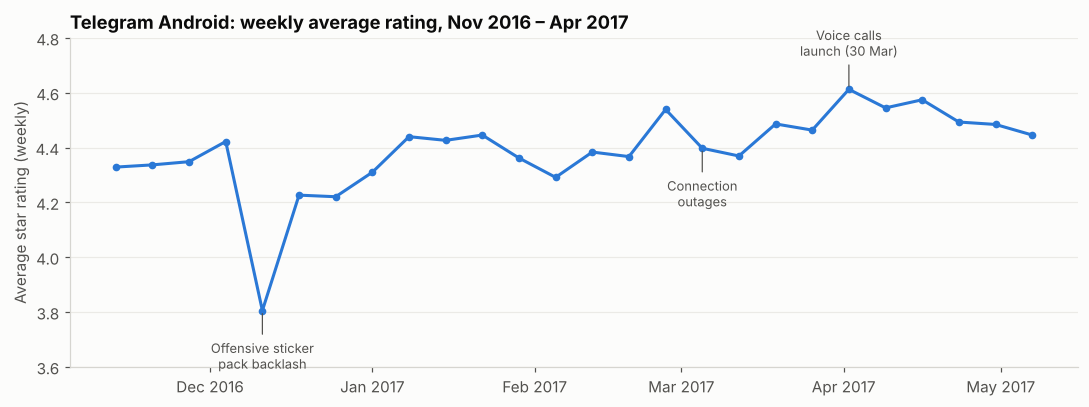

In [7]:
LAUNCH = pd.Timestamp("2017-03-30")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(weekly.index, weekly["avg"], color=C["blue"], marker="o", ms=4)
ax.set_ylim(3.6, 4.8)
ax.set_ylabel("Average star rating (weekly)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
events = [
    (pd.Timestamp("2016-12-11"), "Offensive sticker\npack backlash", -0.08),
    (pd.Timestamp("2017-03-05"), "Connection\noutages", -0.18),
    (pd.Timestamp("2017-04-02"), "Voice calls\nlaunch (30 Mar)", 0.1),
]
for d, label, dy in events:
    y = weekly["avg"].asof(d)
    ax.annotate(label, (d, y), xytext=(0, -38 if dy < 0 else 22), textcoords="offset points", ha="center", fontsize=8.5,
                color=C["ink2"], arrowprops=dict(arrowstyle="-", color=C["ink2"], lw=0.8))
ax.set_title("Telegram Android: weekly average rating, Nov 2016 – Apr 2017")
save(fig, "01_weekly_rating_events")
plt.show()

## 3. Launch analysis: voice calls (30 March 2017)
Calls were a long-requested feature. They launched in Western Europe first, with other regions "very soon".

In [8]:
calls = df[df["Voice & video calls"]].copy()
calls["period"] = np.where(calls["date"] >= LAUNCH, "after launch", "before launch")
calls_summary = calls.groupby("period").agg(
    reviews=("star", "size"), avg_rating=("star", "mean"), low_share=("low", "mean"), request_share=("request", "mean"))
pre, post = df[df.date < LAUNCH], df[df.date >= LAUNCH]
calls_summary["share_of_all_reviews"] = [len(calls[calls.period == p]) / len(x) for p, x in
                                         [("after launch", post), ("before launch", pre)]]
calls_summary.loc[["before launch", "after launch"]]

,reviews,avg_rating,low_share,request_share,share_of_all_reviews
period,,,,,
before launch,887,4.124014,0.092446,0.227734,0.050415
after launch,544,4.332721,0.091912,0.158088,0.104175


In [9]:
post_low_calls = calls[(calls.period == "after launch") & calls.low]
avail = is_availability_issue(post_low_calls["review"])
print(f"After launch, {len(post_low_calls)} low-star reviews mention calls; {avail.mean():.0%} of them are about "
      "the feature not being visible/available yet (regional rollout), not about call quality.")
post_low_calls.loc[avail, "review"].str[:110].head(6).to_list()

After launch, 50 low-star reviews mention calls; 46% of them are about the feature not being visible/available yet (regional rollout), not about call quality.


["ALL THOSE WHO ARE UPDATING  PLEASE READ THIS. I updated the app on 30th March  that's the latest update introd",
 "Where's that call icon! Nothing!",
 'This update is no voice call 👎',
 'Calls does not appears anywhere  sucks',
 "I downloaded the last update   where's the Voice calls ? fix it plz",
 "Updated to the latest version but no call option can be seen plz plz plz plz help I need this option .....It's"]

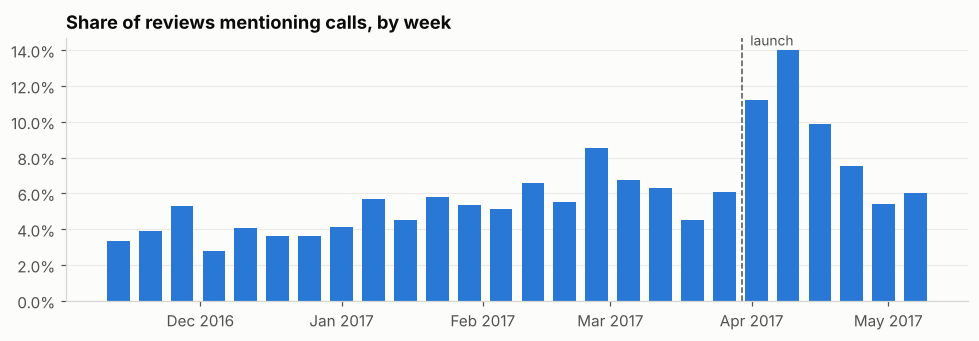

In [10]:
call_weekly = df.set_index("date").resample("W")["Voice & video calls"].mean()
call_weekly = call_weekly[weekly.index]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(call_weekly.index, call_weekly.values, width=5, color=C["blue"])
ax.axvline(LAUNCH, color=C["ink2"], ls="--", lw=1)
ax.text(LAUNCH, call_weekly.max() * 1.02, "  launch", color=C["ink2"], fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Share of reviews mentioning calls, by week")
save(fig, "02_calls_mentions_weekly")
plt.show()

## 4. Theme analysis
For each theme: how often it appears, how users who mention it rate the app, and what share of **all** 1–2★ reviews it explains.
The 281 reviews about the offensive sticker pack are **excluded** here: that was a one-off trust & safety incident, and
leaving it in would make "Stickers & emoji" look like a product problem (its average jumps from 3.1★ to 4.2★ once excluded).

In [11]:
INCIDENT = "Offensive sticker pack (incident)"
base = df[~df[INCIDENT]]
overall_avg = df["star"].mean()
rows = []
for t in THEMES:
    if t == INCIDENT:
        continue
    m = base[t]
    rows.append({
        "theme": t, "reviews": int(m.sum()), "share_of_reviews": m.mean(), "avg_rating": base.loc[m, "star"].mean(),
        "low_star_share": base.loc[m, "low"].mean(), "share_of_all_low_star": (m & base.low).sum() / base.low.sum(),
        "dissatisfied_reviews": int((m & (base.star <= 3)).sum()),
    })
theme_table = pd.DataFrame(rows).set_index("theme")
theme_table["rating_gap"] = overall_avg - theme_table["avg_rating"]
theme_table = theme_table.sort_values("share_of_all_low_star", ascending=False)
theme_table.style.format({"share_of_reviews": "{:.1%}", "avg_rating": "{:.2f}", "low_star_share": "{:.0%}",
                          "share_of_all_low_star": "{:.1%}", "rating_gap": "{:+.2f}"})

,reviews,share_of_reviews,avg_rating,low_star_share,share_of_all_low_star,dissatisfied_reviews,rating_gap
theme,,,,,,,
Media & file sharing,1832,8.1%,3.99,15%,14.9%,504,+0.40
Crashes & bugs,303,1.3%,2.90,44%,7.2%,187,+1.49
Voice & video calls,1430,6.3%,4.20,9%,7.1%,296,+0.19
Notifications,328,1.5%,3.21,31%,5.5%,178,+1.18
Message controls,415,1.8%,3.67,20%,4.5%,159,+0.72
Privacy & security,718,3.2%,4.24,11%,4.4%,154,+0.15
"Groups, channels & bots",717,3.2%,4.13,11%,4.3%,162,+0.26
Login & verification,123,0.5%,2.46,63%,4.2%,86,+1.93
Connection & sync,269,1.2%,3.56,28%,4.1%,115,+0.83


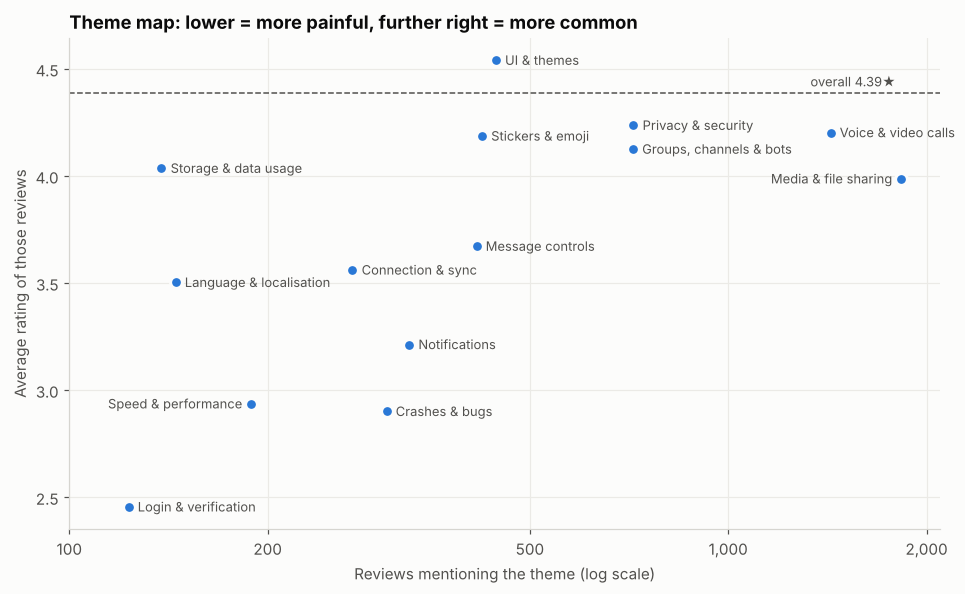

In [12]:
plot = theme_table.copy()
plot = plot[plot["reviews"] >= 50]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(plot["reviews"], plot["avg_rating"], s=60, color=C["blue"], edgecolor=C["surface"], linewidth=2, zorder=3)
left_labels = {"Speed & performance", "Media & file sharing"}
for name, r in plot.iterrows():
    left = name in left_labels
    ax.annotate(name, (r["reviews"], r["avg_rating"]), xytext=(-6 if left else 6, -3), textcoords="offset points",
                ha="right" if left else "left", fontsize=8.5, color=C["ink2"])
ax.axhline(overall_avg, color=C["ink2"], ls="--", lw=1)
ax.text(plot["reviews"].max() * 0.98, overall_avg + 0.03, f"overall {overall_avg:.2f}★", ha="right", fontsize=8.5, color=C["ink2"])
ax.set_xscale("log")
ax.set_xticks([100, 200, 500, 1000, 2000], ["100", "200", "500", "1,000", "2,000"])
ax.minorticks_off()
ax.set_xlabel("Reviews mentioning the theme (log scale)")
ax.set_ylabel("Average rating of those reviews")
ax.set_title("Theme map: lower = more painful, further right = more common")
ax.grid(axis="x")
save(fig, "03_theme_map")
plt.show()

### Cross-check with unsupervised topic modelling (NMF)
Keyword rules can miss things. NMF on the 1–2★ reviews with at least 6 words (incident excluded, generic praise/insult words
removed) finds topics without any rules. If they line up with the taxonomy, the taxonomy covers the main pain points.

In [13]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
generic = {"app", "telegram", "good", "nice", "bad", "worst", "ok", "super", "awesome", "best", "great", "like", "just",
           "really", "use", "using", "apps", "application", "plz", "pls", "please", "dont", "don", "im", "love"}
neg = base[base.low & (base["review"].str.split().str.len() >= 6)]["review"].str.lower()
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | generic), min_df=5, max_df=0.4, ngram_range=(1, 2))
X = tfidf.fit_transform(neg)
nmf = NMF(n_components=10, random_state=0, init="nndsvda", max_iter=800).fit(X)
terms = tfidf.get_feature_names_out()
print(f"{len(neg):,} reviews modelled")
for k, comp in enumerate(nmf.components_):
    print(f"Topic {k + 1:>2}: " + ", ".join(terms[comp.argsort()[::-1][:8]]))

1,145 reviews modelled
Topic  1: notification, notifications, open, messages, message, getting, new, doesn
Topic  2: phone, number, phone number, contacts, work, keeps, account, contact
Topic  3: video, voice, calling, voice video, better, video calling, add, send
Topic  4: download, slow, downloading, hate, file, pictures, speed, time
Topic  5: update, new, new update, fix, update update, version, need, day
Topic  6: persian, language, add, persian language, add persian, support, iran, language persian
Topic  7: chat, group, delete, option, add, need, group chat, secret
Topic  8: videos, photos, gif, photos videos, fast, whatapp, increase, increase number
Topic  9: working, connecting, whatsapp, help, fix, network, know, pictures
Topic 10: indian, people, india, whatsapp, tell, saying, save, support


The unsupervised topics map onto the taxonomy: notifications, phone number / account (login & verification), voice and video
calling, slow downloads and media limits (media & file sharing), updates breaking things (crashes & bugs), connection problems,
and group/delete options (message controls). One topic the keyword rules under-count is **Persian-language support**, a
localisation request from users in Iran.

## 5. Feature requests

In [14]:
req = df[df["request"]]
print(f"{len(req):,} reviews ({df.request.mean():.1%}) contain an explicit request")
req_themes = req[list(THEMES)].mean().sort_values(ascending=False).head(8)
req_themes.rename("share_of_requests").to_frame().style.format("{:.1%}")

779 reviews (3.4%) contain an explicit request


,share_of_requests
Voice & video calls,37.0%
Media & file sharing,33.8%
"Groups, channels & bots",13.4%
Message controls,8.0%
UI & themes,7.6%
Privacy & security,7.2%
Stickers & emoji,6.8%
Language & localisation,5.3%


## 6. RICE prioritisation
Each candidate initiative is tied to a theme. The sticker-pack incident is **not** scored: it is handled as an immediate
trust & safety action (a review step for new sticker packs plus an in-app report button), outside the backlog.
- **Reach**: dissatisfied (≤3★) reviews per quarter that mention the theme, a proxy for how many unhappy users it touches.
- **Impact**: from the rating gap (overall average minus theme average): ≥1.25★ → 3, ≥0.75★ → 2, ≥0.4★ → 1, otherwise 0.5.
- **Confidence**: 80% if 100+ dissatisfied reviews support the theme, otherwise 50%.
- **Effort**: person-months. **This is my own judgement** as the PM, written down so engineering can challenge it.

In [15]:
# The calls initiative targets only the availability complaints, not every review that mentions calls
calls_avail = base["Voice & video calls"] & is_availability_issue(base["review"])
theme_table.loc["Calls: availability complaints"] = {
    "reviews": int(calls_avail.sum()), "avg_rating": base.loc[calls_avail, "star"].mean(),
    "dissatisfied_reviews": int((calls_avail & (base.star <= 3)).sum()),
    "rating_gap": overall_avg - base.loc[calls_avail, "star"].mean(),
}

initiatives = pd.DataFrame([
    ("Crash & stability programme", "Crashes & bugs", 4),
    ("Reliable notifications (delivery + diagnostics)", "Notifications", 3),
    ("Faster media downloads on slow networks", "Media & file sharing", 4),
    ("Calls: in-app 'coming to your region' messaging", "Calls: availability complaints", 1),
    ("Faster, more reliable login & SMS verification", "Login & verification", 2),
    ("Message controls: unsend / edit", "Message controls", 2),
    ("Connection resilience on weak networks", "Connection & sync", 5),
    ("Localisation (Persian, Indian languages)", "Language & localisation", 3),
    ("Storage manager: clear cache by chat", "Storage & data usage", 2),
], columns=["initiative", "theme", "effort_pm"])

months = (df.date.max() - df.date.min()).days / 30.4
dissat = initiatives["theme"].map(theme_table["dissatisfied_reviews"])
initiatives["reach_per_quarter"] = dissat / months * 3
gap = initiatives["theme"].map(theme_table["rating_gap"])
initiatives["impact"] = np.select([gap >= 1.25, gap >= 0.75, gap >= 0.4], [3, 2, 1], default=0.5)
initiatives["confidence"] = np.where(dissat >= 100, 0.8, 0.5)
initiatives["rice"] = initiatives["reach_per_quarter"] * initiatives["impact"] * initiatives["confidence"] / initiatives["effort_pm"]
initiatives = initiatives.sort_values("rice", ascending=False).reset_index(drop=True)
initiatives.index += 1
initiatives.style.format({"reach_per_quarter": "{:.0f}", "impact": "{:.1f}", "confidence": "{:.0%}", "rice": "{:.0f}"})

,initiative,theme,effort_pm,reach_per_quarter,impact,confidence,rice
1,Crash & stability programme,Crashes & bugs,4,99,3.0,80%,59
2,Faster media downloads on slow networks,Media & file sharing,4,266,1.0,80%,53
3,Reliable notifications (delivery + diagnostics),Notifications,3,94,2.0,80%,50
4,"Faster, more reliable login & SMS verification",Login & verification,2,45,3.0,50%,34
5,Message controls: unsend / edit,Message controls,2,84,1.0,80%,34
6,Connection resilience on weak networks,Connection & sync,5,61,2.0,80%,19
7,Calls: in-app 'coming to your region' messaging,Calls: availability complaints,1,37,1.0,50%,19
8,"Localisation (Persian, Indian languages)",Language & localisation,3,29,2.0,50%,10
9,Storage manager: clear cache by chat,Storage & data usage,2,19,0.5,50%,2


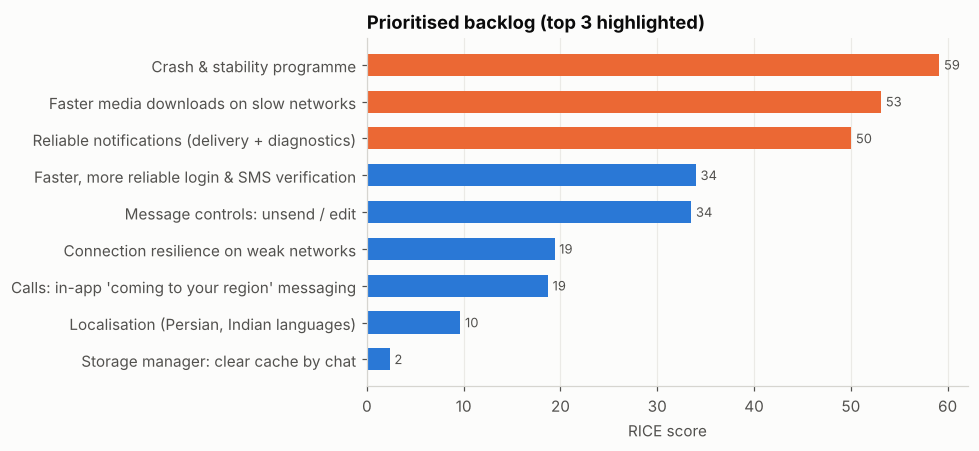

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.2))
r = initiatives.iloc[::-1]
bars = ax.barh(r["initiative"], r["rice"], color=[C["blue"] if i > 3 else C["orange"] for i in r.index], height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in r["rice"]], padding=3, fontsize=8.5, color=C["ink2"])
ax.set_xlabel("RICE score")
ax.set_title("Prioritised backlog (top 3 highlighted)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
save(fig, "04_rice_backlog")
plt.show()

## 7. Summary

In [17]:
cs = calls_summary
tt = theme_table
print(f"""
- {len(df):,} reviews, average {overall_avg:.2f} stars, {df.low.mean():.1%} are 1-2 stars.
- Biggest dip: 8-11 Dec 2016 (avg {inc.star.mean():.2f}), driven by an offensive sticker pack: a trust & safety gap, not a product bug.
- Voice calls launch: call mentions rose from {cs.loc['before launch','share_of_all_reviews']:.1%} to {cs.loc['after launch','share_of_all_reviews']:.1%} of reviews and their
  average rating from {cs.loc['before launch','avg_rating']:.2f} to {cs.loc['after launch','avg_rating']:.2f}; {avail.mean():.0%} of post-launch low-star call reviews were about regional availability.
- Most painful recurring themes (avg rating): Login & verification {tt.loc['Login & verification','avg_rating']:.2f},
  Crashes & bugs {tt.loc['Crashes & bugs','avg_rating']:.2f}, Notifications {tt.loc['Notifications','avg_rating']:.2f},
  Connection & sync {tt.loc['Connection & sync','avg_rating']:.2f}.
- Top RICE item: {initiatives.loc[1,'initiative']} (score {initiatives.loc[1,'rice']:.0f}).
""")


- 22,816 reviews, average 4.39 stars, 9.3% are 1-2 stars.
- Biggest dip: 8-11 Dec 2016 (avg 3.57), driven by an offensive sticker pack: a trust & safety gap, not a product bug.
- Voice calls launch: call mentions rose from 5.0% to 10.4% of reviews and their
  average rating from 4.12 to 4.33; 46% of post-launch low-star call reviews were about regional availability.
- Most painful recurring themes (avg rating): Login & verification 2.46,
  Crashes & bugs 2.90, Notifications 3.21,
  Connection & sync 3.56.
- Top RICE item: Crash & stability programme (score 59).

